In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## a. Load the dataset and perform exploratory data analysis (EDA).

In [2]:
df=pd.read_csv('diabetes.csv')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

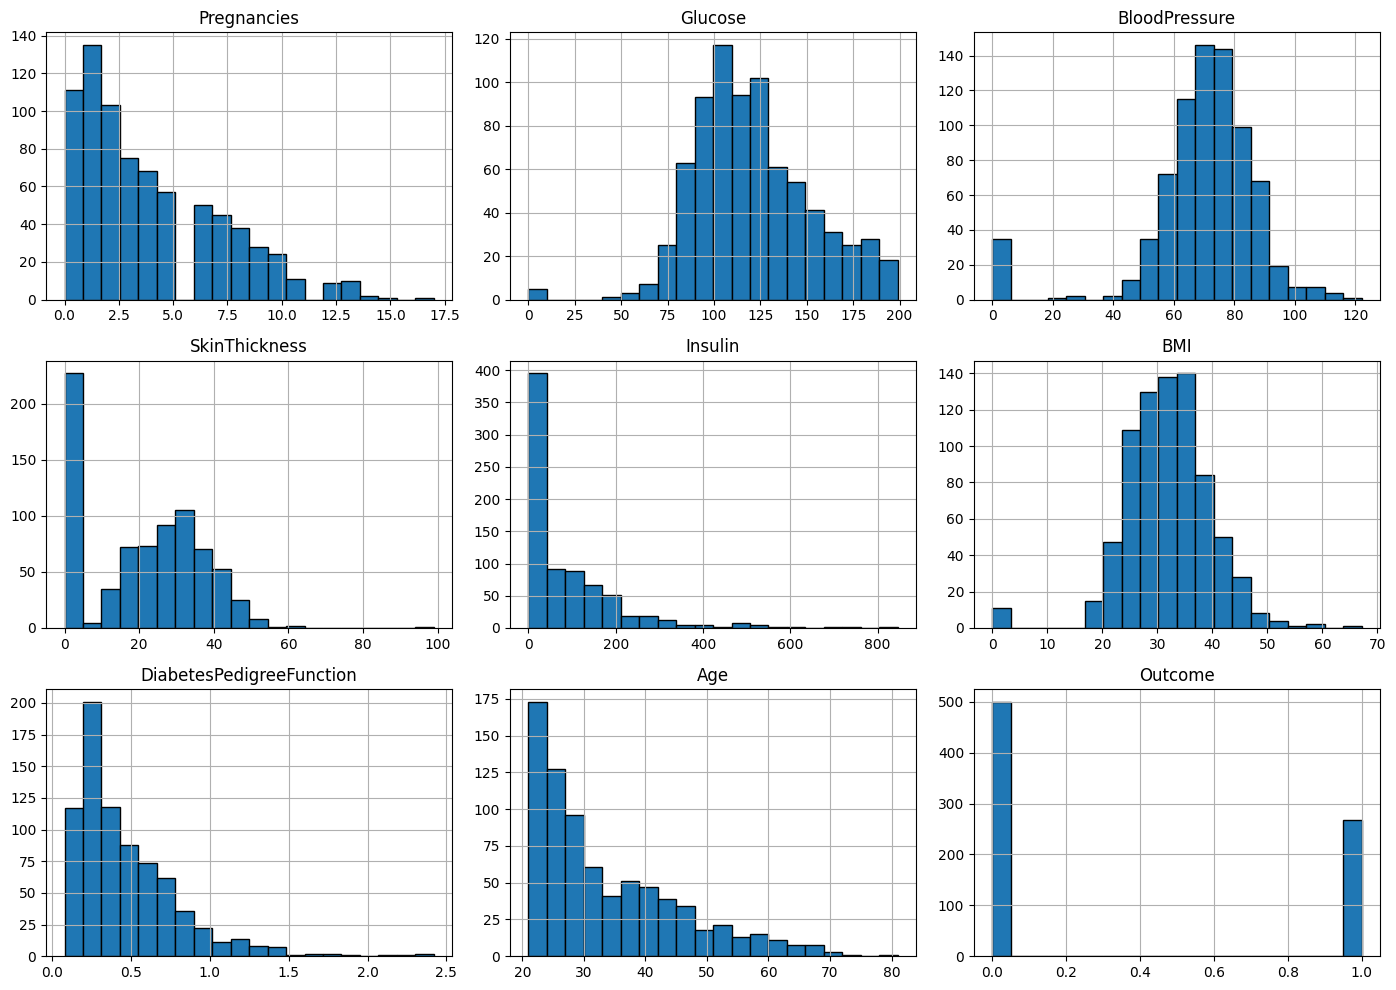

In [10]:
df.hist(figsize=(14, 10), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

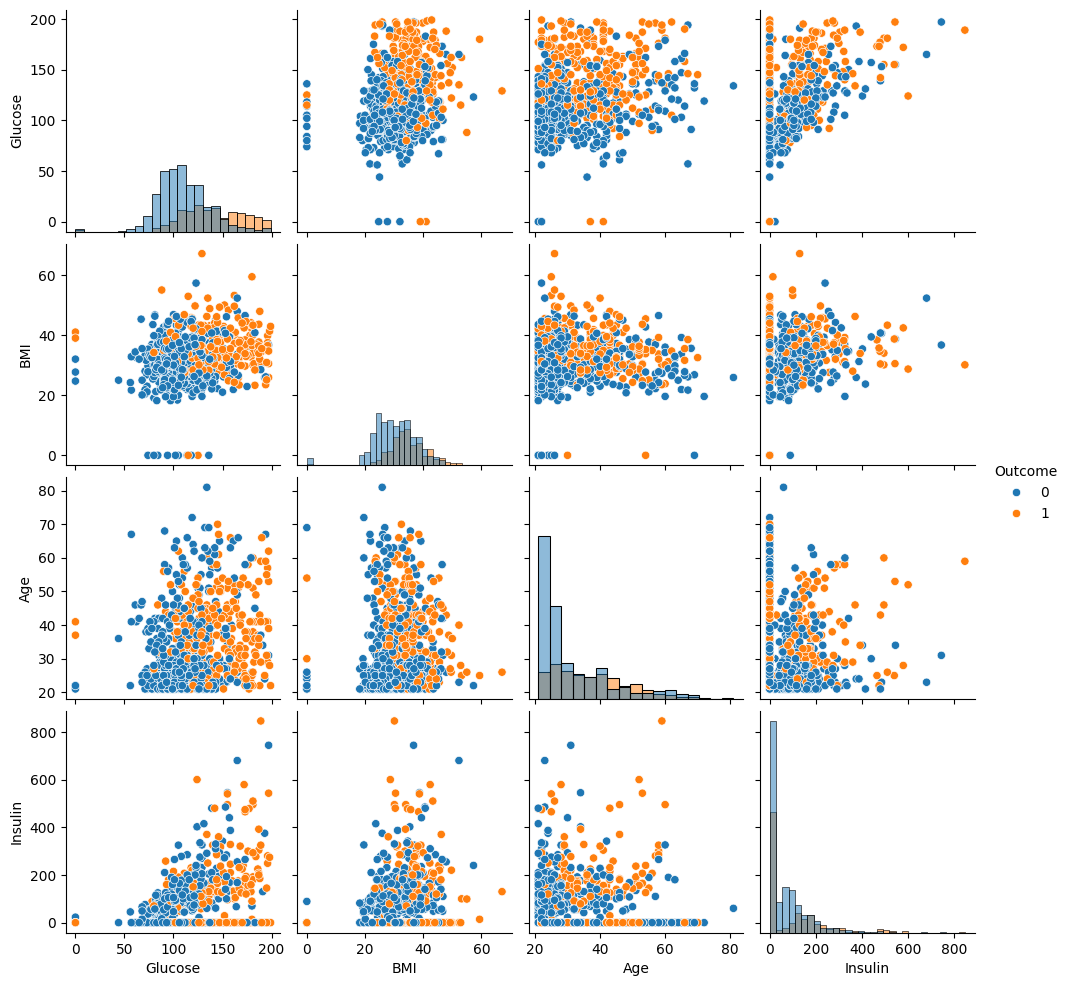

In [11]:
sns.pairplot(
    df,
    vars=['Glucose', 'BMI', 'Age', 'Insulin'],
    hue='Outcome',
    diag_kind='hist'
)
plt.show()

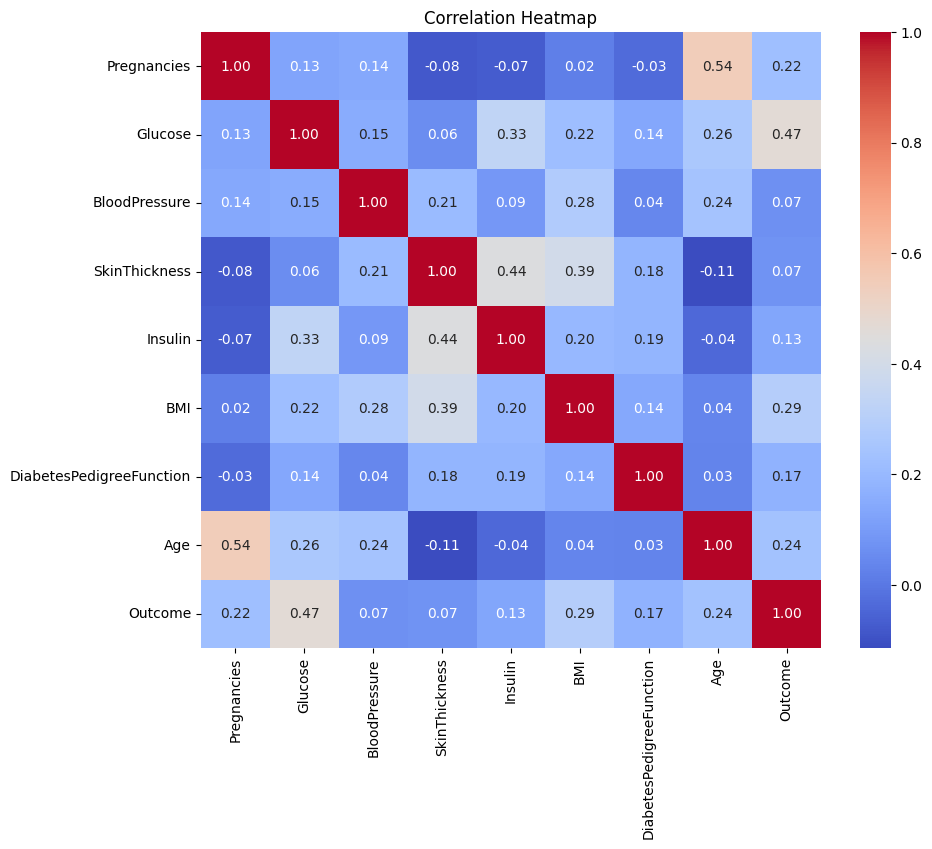

In [12]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

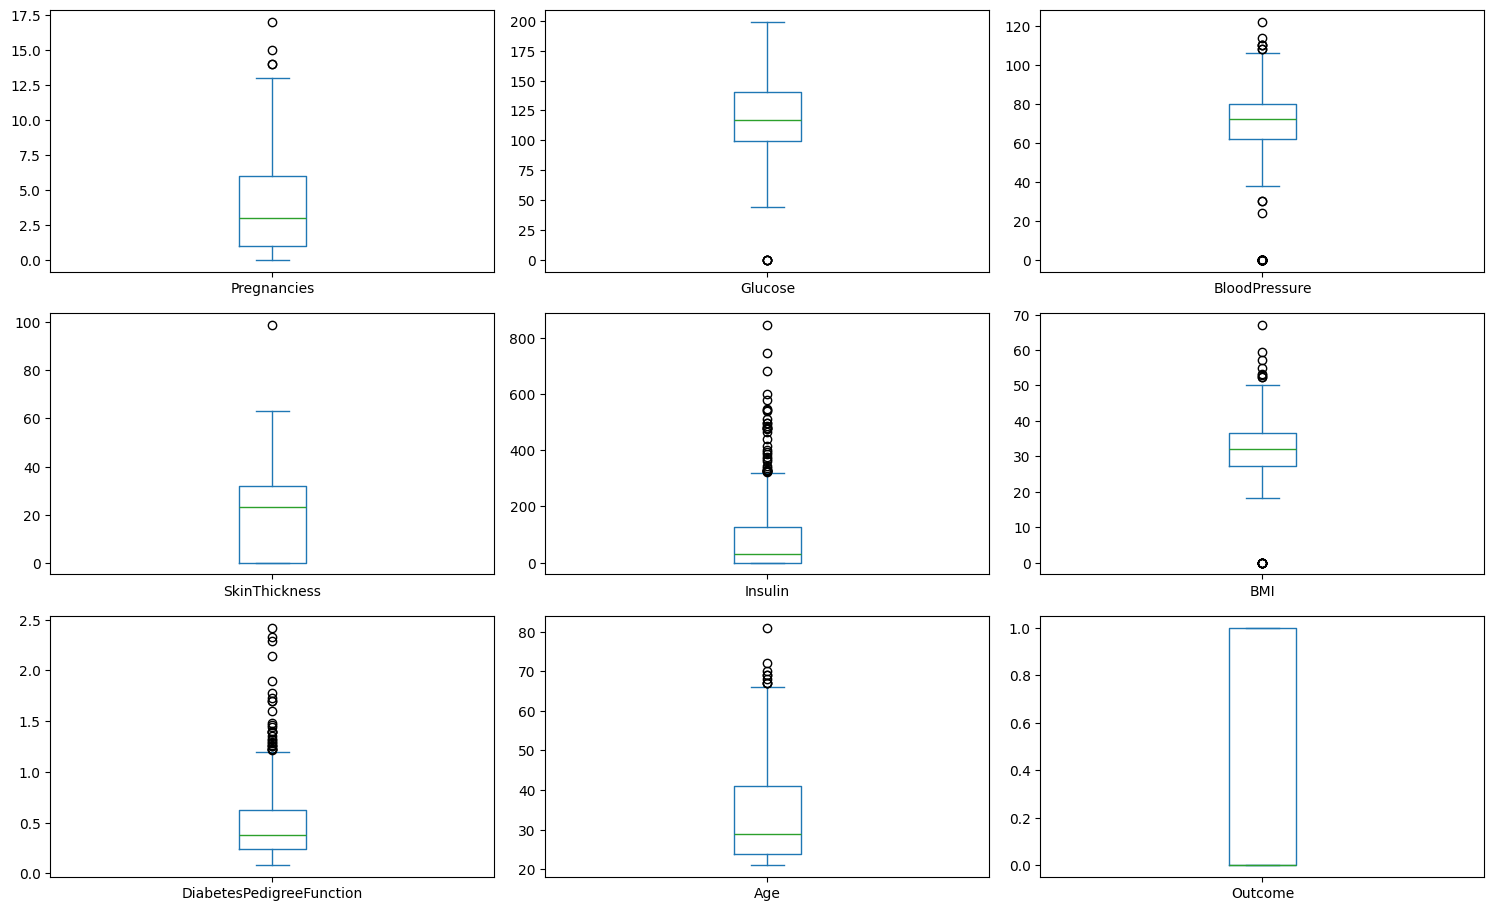

In [13]:
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include='number').columns

df[num_cols].plot(
    kind='box',
    subplots=True,
    layout=(4, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [14]:
cols = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print((df[cols] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [15]:
import numpy as np

cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[cols] = df[cols].replace(0, np.nan)

In [16]:
df[cols].isnull().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [17]:
for col in cols:
    df[col] = df[col].fillna(df[col].median())

In [18]:
df[cols].isnull().sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

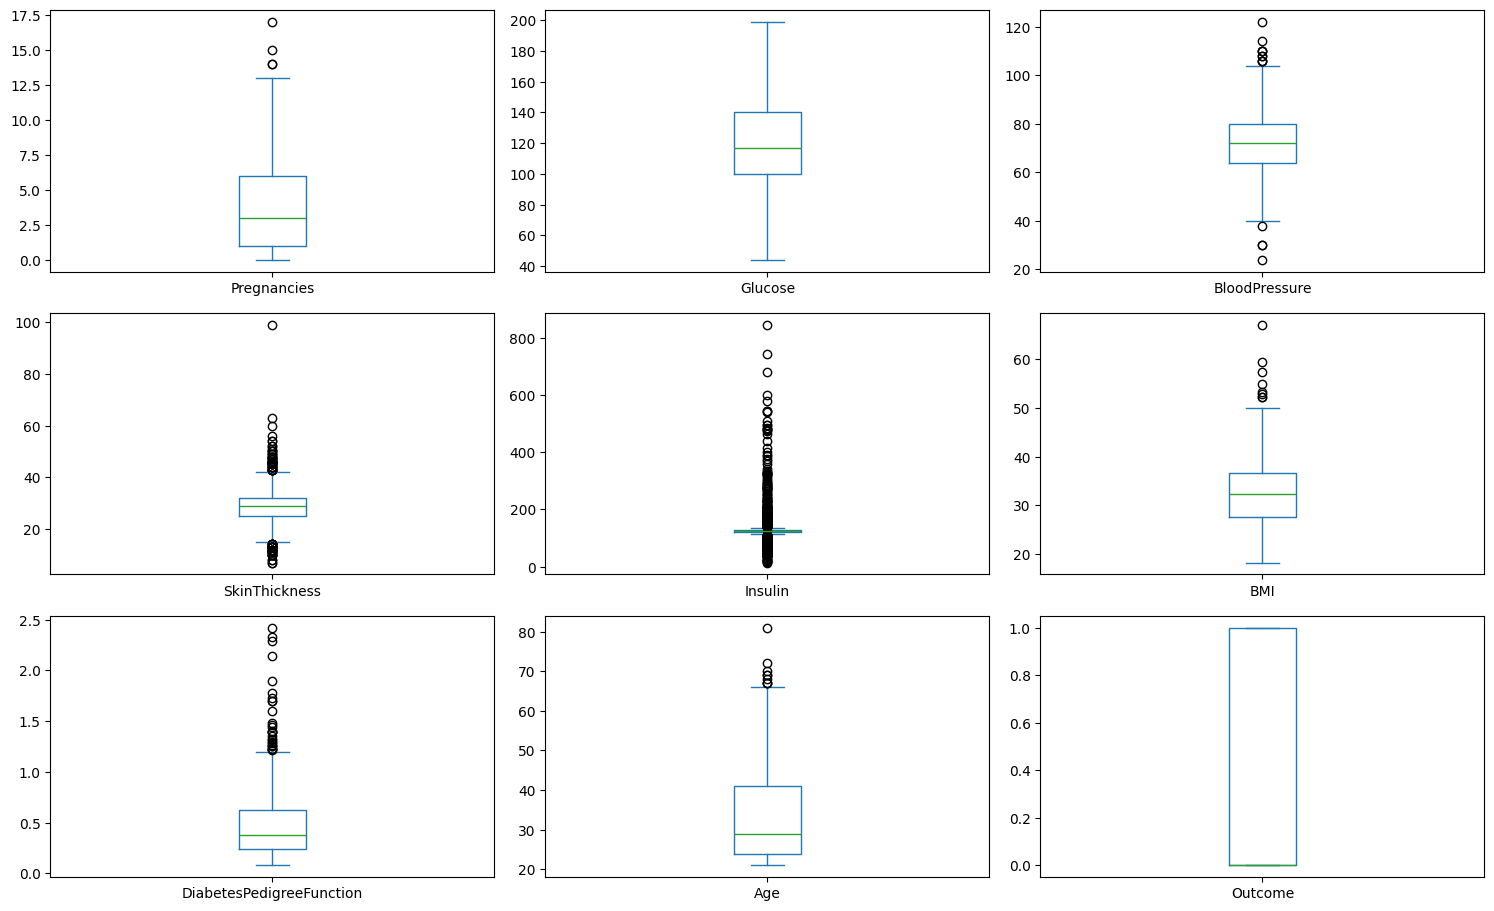

In [19]:
num_cols = df.select_dtypes(include='number').columns

df[num_cols].plot(
    kind='box',
    subplots=True,
    layout=(4, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

## Analysis of Patterns and Correlations
The correlation heatmap indicates that Glucose has the strongest positive linear correlation with the diabetes outcome, with a correlation coefficient of 0.49. BMI shows a positive correlation of 0.31, followed by Age (0.24), Pregnancies (0.22), SkinThickness (0.21), Insulin (0.20), BloodPressure (0.17), and DiabetesPedigreeFunction (0.17).

These findings suggest that higher glucose and BMI measurements are more strongly associated with the positive diabetes outcome than the other individual features in this dataset. Positive correlations are also observed between Age and Pregnancies (0.54), SkinThickness and BMI (0.54), and Glucose and Insulin (0.42).

Overall, Glucose appears to be an important candidate predictor for the logistic regression model. However, correlation alone does not determine predictive importance or establish causation. The features will therefore be evaluated together using appropriate classification metrics on unseen test data.

In [20]:
num_cols = df.select_dtypes(include='number').columns.drop('Outcome')

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (df[num_cols] < lower_bound) |
    (df[num_cols] > upper_bound)
).sum()

print(outlier_count.sort_values(ascending=False))

Insulin                     346
SkinThickness                87
DiabetesPedigreeFunction     29
BloodPressure                14
Age                           9
BMI                           8
Pregnancies                   4
Glucose                       0
dtype: int64


In [21]:
outlier_summary = pd.DataFrame({
    'Minimum': df[num_cols].min(),
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Maximum': df[num_cols].max(),
    'Outlier Count': outlier_count
})

outlier_summary

,Minimum,Lower Bound,Upper Bound,Maximum,Outlier Count
Pregnancies,0.000,-6.500,13.500,17.00,4
Glucose,44.000,39.000,201.000,199.00,0
BloodPressure,24.000,40.000,104.000,122.00,14
SkinThickness,7.000,14.500,42.500,99.00,87
Insulin,14.000,112.875,135.875,846.00,346
BMI,18.200,13.850,50.250,67.10,8
DiabetesPedigreeFunction,0.078,-0.330,1.200,2.42,29
Age,21.000,-1.500,66.500,81.00,9


In [22]:
for col in num_cols:
    mask = (df[col] < lower_bound[col]) | (df[col] > upper_bound[col])

    print(f"\n{col}: {mask.sum()} outliers")
    print(df.loc[mask, col].sort_values().to_list())


Pregnancies: 4 outliers
[14, 14, 15, 17]

Glucose: 0 outliers
[]

BloodPressure: 14 outliers
[24.0, 30.0, 30.0, 38.0, 106.0, 106.0, 106.0, 108.0, 108.0, 110.0, 110.0, 110.0, 114.0, 122.0]

SkinThickness: 87 outliers
[7.0, 7.0, 8.0, 8.0, 10.0, 10.0, 10.0, 10.0, 10.0, 11.0, 11.0, 11.0, 11.0, 11.0, 11.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 12.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 13.0, 14.0, 14.0, 14.0, 14.0, 14.0, 14.0, 43.0, 43.0, 43.0, 43.0, 43.0, 43.0, 44.0, 44.0, 44.0, 44.0, 44.0, 45.0, 45.0, 45.0, 45.0, 45.0, 45.0, 46.0, 46.0, 46.0, 46.0, 46.0, 46.0, 46.0, 46.0, 47.0, 47.0, 47.0, 47.0, 48.0, 48.0, 48.0, 48.0, 49.0, 49.0, 49.0, 50.0, 50.0, 50.0, 51.0, 52.0, 52.0, 54.0, 54.0, 56.0, 60.0, 63.0, 99.0]

Insulin: 346 outliers
[14.0, 15.0, 16.0, 18.0, 18.0, 22.0, 23.0, 23.0, 25.0, 29.0, 32.0, 36.0, 36.0, 36.0, 37.0, 37.0, 38.0, 40.0, 40.0, 41.0, 42.0, 43.0, 44.0, 44.0, 44.0, 45.0, 45.0, 45.0, 46.0, 48.0, 48.0, 48.0, 49.0, 49.0, 49.0, 49.0, 49.0, 50.0, 50.0, 50.0, 

In [23]:
skewness = df[num_cols].skew().sort_values(ascending=False)

print(skewness)

Insulin                     3.380019
DiabetesPedigreeFunction    1.919911
Age                         1.129597
Pregnancies                 0.901674
SkinThickness               0.837608
BMI                         0.599233
Glucose                     0.535587
BloodPressure               0.141885
dtype: float64


In [24]:
import numpy as np

df_model = df.copy()

df_model['Insulin'] = np.log1p(df_model['Insulin'])
df_model['DiabetesPedigreeFunction'] = np.log1p(
    df_model['DiabetesPedigreeFunction']
)

In [25]:
df_model[['Insulin', 'DiabetesPedigreeFunction']].skew()

Insulin                    -0.175078
DiabetesPedigreeFunction    1.117942
dtype: float64

In [26]:
X = df_model.drop('Outcome', axis=1)
y = df_model['Outcome']

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [30]:
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

In [31]:
from sklearn.metrics import accuracy_score
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.3f}")
print(f"Testing Accuracy:  {test_accuracy:.3f}")

Training Accuracy: 0.788
Testing Accuracy:  0.701


              precision    recall  f1-score   support

 No Diabetes       0.75      0.81      0.78       100
    Diabetes       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



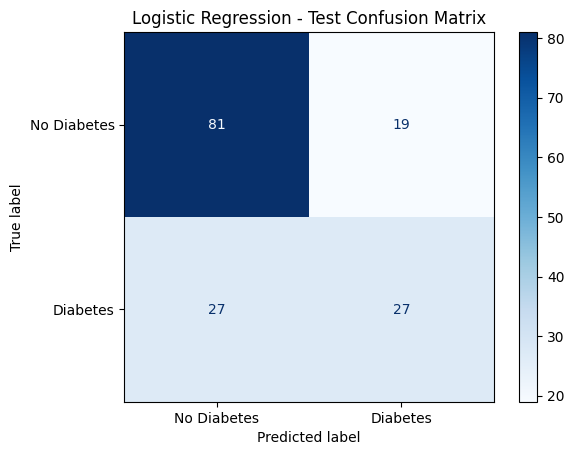

In [32]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print(classification_report(
    y_test,
    y_test_pred,
    target_names=['No Diabetes', 'Diabetes'],
    zero_division=0
))

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Diabetes', 'Diabetes']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Test Confusion Matrix')
plt.show()

Test ROC-AUC: 0.812


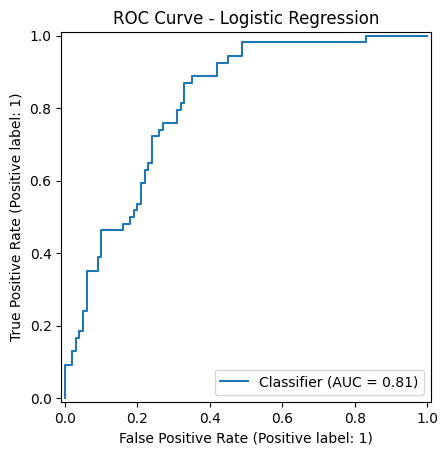

In [33]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_test_proba)

print(f"Test ROC-AUC: {auc:.3f}")

RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title('ROC Curve - Logistic Regression')
plt.show()

In [34]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get predicted probabilities for the positive class (Diabetes = 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Test different classification thresholds
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))


   Threshold  Accuracy  Precision  Recall  F1-Score
0       0.30     0.351      0.351     1.0     0.519
1       0.35     0.351      0.351     1.0     0.519
2       0.40     0.351      0.351     1.0     0.519
3       0.45     0.351      0.351     1.0     0.519
4       0.50     0.351      0.351     1.0     0.519
5       0.55     0.351      0.351     1.0     0.519
6       0.60     0.351      0.351     1.0     0.519


C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [35]:
# Inspect predicted probabilities
print("Minimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())

print("\nFirst 20 probabilities:")
print(y_prob[:20])

print("\nActual class distribution:")
print(y_test.value_counts())

print("\nPredictions at threshold 0.50:")
y_pred_05 = (y_prob >= 0.50).astype(int)
print(pd.Series(y_pred_05).value_counts())

Minimum probability: 1.0
Maximum probability: 1.0

First 20 probabilities:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Actual class distribution:
Outcome
0    100
1     54
Name: count, dtype: int64

Predictions at threshold 0.50:
1    154
Name: count, dtype: int64


In [36]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_05))

[[  0 100]
 [  0  54]]


In [37]:

print("Model:", model)
print("Model type:", type(model))

print("\nModel classes:")
print(model.classes_)

print("\nModel coefficients:")
print(model.coef_)

print("\nModel intercept:")
print(model.intercept_)

print("\nFirst 5 test rows:")
print(X_test.head())

print("\nPredicted probabilities for first 5 rows:")
print(model.predict_proba(X_test.iloc[:5]))


Model: LogisticRegression(max_iter=1000, random_state=42)
Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>

Model classes:
[0 1]

Model coefficients:
[[ 0.37532877  1.12528828 -0.03795738  0.01963428  0.08290842  0.6691013
   0.25631742  0.15038589]]

Model intercept:
[-0.87881006]

First 5 test rows:
     Pregnancies  Glucose  BloodPressure  SkinThickness   Insulin   BMI  \
44             7    159.0           64.0           29.0  4.836282  27.4   
672           10     68.0          106.0           23.0  3.912023  35.5   
700            2    122.0           76.0           27.0  5.303305  35.9   
630            7    114.0           64.0           29.0  4.836282  27.4   
81             2     74.0           72.0           29.0  4.836282  32.3   

     DiabetesPedigreeFunction  Age  
44                   0.257738   40  
672                  0.250759   47  
700                  0.394067   26  
630                  0.549277   34  
81                   0.097127   22  



C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [38]:

import numpy as np

# Check probability output for the first five test rows
proba = model.predict_proba(X_test.iloc[:5])

print("Raw probabilities:")
print(repr(proba))

print("\nProbability range for class 1:")
all_proba = model.predict_proba(X_test)[:, 1]
print("Minimum:", all_proba.min())
print("Maximum:", all_proba.max())

print("\nNumber of unique probabilities:")
print(len(np.unique(all_proba)))

print("\nModel coefficient magnitude:")
print("Largest absolute coefficient:", np.abs(model.coef_).max())


Raw probabilities:
array([[0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.]])

Probability range for class 1:
Minimum: 1.0
Maximum: 1.0

Number of unique probabilities:
1

Model coefficient magnitude:
Largest absolute coefficient: 1.1252882818665702


C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [39]:

print("Training data summary:")
print(X_train.describe().T)

print("\nTest data summary:")
print(X_test.describe().T)

print("\nTraining data first five rows:")
print(X_train.head())


Training data summary:
                          count        mean        std        min        25%  \
Pregnancies               614.0    3.819218   3.314148   0.000000   1.000000   
Glucose                   614.0  121.671010  30.003794  56.000000  99.000000   
BloodPressure             614.0   72.140065  12.275119  24.000000  64.000000   
SkinThickness             614.0   29.042345   8.891855   7.000000  25.000000   
Insulin                   614.0    4.813452   0.488608   2.772589   4.795791   
BMI                       614.0   32.446743   6.824142  18.200000  27.625000   
DiabetesPedigreeFunction  614.0    0.369165   0.198581   0.080658   0.219136   
Age                       614.0   33.366450  11.833438  21.000000  24.000000   

                                 50%         75%         max  
Pregnancies                 3.000000    6.000000   17.000000  
Glucose                   117.000000  140.000000  199.000000  
BloodPressure              72.000000   80.000000  122.000000  
Skin

In [40]:

import numpy as np
import pandas as pd

# Calculate the raw linear scores: X multiplied by coefficients + intercept
scores = np.dot(X_test.to_numpy(), model.coef_.ravel()) + model.intercept_[0]

print("Raw decision scores:")
print(pd.Series(scores).describe())

print("\nFirst 10 raw scores:")
print(scores[:10])

print("\nFirst 10 model probabilities:")
print(model.predict_proba(X_test)[:10])

print("\nLargest and smallest raw scores:")
print("Minimum:", scores.min())
print("Maximum:", scores.max())

print("\nCheck for non-finite feature values:")
print("Training data:", np.isfinite(X_train.to_numpy()).all())
print("Test data:", np.isfinite(X_test.to_numpy()).all())


Raw decision scores:
count    154.000000
mean     162.383381
std       38.177543
min       71.387327
25%      133.135401
50%      156.890439
75%      187.306520
max      248.753308
dtype: float64

First 10 raw scores:
[203.62529233 107.0320332  163.27384708 152.15973071 106.32596824
 136.53729586 153.3855354  245.36294596 133.93468945 219.23203121]

First 10 model probabilities:
[[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]

Largest and smallest raw scores:
Minimum: 71.38732668952257
Maximum: 248.7533084603512

Check for non-finite feature values:
Training data: True
Test data: True


C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [41]:

# Show the coefficient associated with each feature
coefficients = pd.Series(
    model.coef_.ravel(),
    index=X_test.columns
)

print("Model coefficients:")
print(coefficients.sort_values(ascending=False))

print("\nMean of each feature in X_train:")
print(X_train.mean().sort_values(ascending=False))

print("\nMean contribution of each feature to the raw score:")
mean_contributions = X_train.mean() * coefficients
print(mean_contributions.sort_values(ascending=False))

print("\nModel intercept:", model.intercept_[0])


Model coefficients:
Glucose                     1.125288
BMI                         0.669101
Pregnancies                 0.375329
DiabetesPedigreeFunction    0.256317
Age                         0.150386
Insulin                     0.082908
SkinThickness               0.019634
BloodPressure              -0.037957
dtype: float64

Mean of each feature in X_train:
Glucose                     121.671010
BloodPressure                72.140065
Age                          33.366450
BMI                          32.446743
SkinThickness                29.042345
Insulin                       4.813452
Pregnancies                   3.819218
DiabetesPedigreeFunction      0.369165
dtype: float64

Mean contribution of each feature to the raw score:
Glucose                     136.914962
BMI                          21.710158
Age                           5.017843
Pregnancies                   1.433462
SkinThickness                 0.570225
Insulin                       0.399076
DiabetesPedigreeFunct

In [42]:
print("Training feature ranges:")
print(X_train.agg(["min", "max"]).T)

print("\nTest feature ranges:")
print(X_test.agg(["min", "max"]).T)

Training feature ranges:
                                min         max
Pregnancies                0.000000   17.000000
Glucose                   56.000000  199.000000
BloodPressure             24.000000  122.000000
SkinThickness              7.000000   99.000000
Insulin                    2.772589    6.613384
BMI                       18.200000   67.100000
DiabetesPedigreeFunction   0.080658    1.202672
Age                       21.000000   81.000000

Test feature ranges:
                                min         max
Pregnancies                0.000000   15.000000
Glucose                   44.000000  197.000000
BloodPressure             48.000000  106.000000
SkinThickness             10.000000   63.000000
Insulin                    2.708050    6.741701
BMI                       18.200000   59.400000
DiabetesPedigreeFunction   0.075107    1.229641
Age                       21.000000   68.000000


In [43]:
print("Training data type:", type(X_train))
print("Test data type:", type(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nModel intercept:", model.intercept_)
print("Model coefficients:", model.coef_)

Training data type: <class 'pandas.core.frame.DataFrame'>
Test data type: <class 'pandas.core.frame.DataFrame'>

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Test target distribution:
Outcome
0    100
1     54
Name: count, dtype: int64

Model intercept: [-0.87881006]
Model coefficients: [[ 0.37532877  1.12528828 -0.03795738  0.01963428  0.08290842  0.6691013
   0.25631742  0.15038589]]


In [44]:
print("Insulin values from the current dataset:")
print(df['Insulin'].head(10))

print("\nInsulin summary:")
print(df['Insulin'].describe())

Insulin values from the current dataset:
0    125.0
1    125.0
2    125.0
3     94.0
4    168.0
5    125.0
6     88.0
7    125.0
8    543.0
9    125.0
Name: Insulin, dtype: float64

Insulin summary:
count    768.000000
mean     140.671875
std       86.383060
min       14.000000
25%      121.500000
50%      125.000000
75%      127.250000
max      846.000000
Name: Insulin, dtype: float64


In [45]:
print("Original data:")
display(df[['Insulin']].head(10))

print("\nTraining data:")
display(X_train[['Insulin']].head(10))

print("\nTest data:")
display(X_test[['Insulin']].head(10))

Original data:


,Insulin
0,125.0
1,125.0
2,125.0
3,94.0
4,168.0
5,125.0
6,88.0
7,125.0
8,543.0
9,125.0



Training data:


,Insulin
353,3.784190
711,3.135494
373,4.553877
46,4.836282
682,4.663439
360,5.786897
414,5.123964
339,4.836282
694,4.836282
33,4.836282



Test data:


,Insulin
44,4.836282
672,3.912023
700,5.303305
630,4.836282
81,4.836282
389,4.406719
387,4.836282
408,4.836282
163,4.836282
335,5.545177


In [46]:
print("Insulin values in X_train:")
print(X_train['Insulin'].describe())

print("\nInsulin values in X_test:")
print(X_test['Insulin'].describe())

Insulin values in X_train:
count    614.000000
mean       4.813452
std        0.488608
min        2.772589
25%        4.795791
50%        4.836282
75%        4.875197
max        6.613384
Name: Insulin, dtype: float64

Insulin values in X_test:
count    154.000000
mean       4.881699
std        0.517237
min        2.708050
25%        4.836282
50%        4.836282
75%        4.836282
max        6.741701
Name: Insulin, dtype: float64


In [47]:
print("Training data feature summary:")
display(X_train.describe().T[['min', 'mean', 'max']])

print("\nOriginal data feature summary:")
display(df.drop(columns='Outcome').describe().T[['min', 'mean', 'max']])

Training data feature summary:


,min,mean,max
Pregnancies,0.000000,3.819218,17.000000
Glucose,56.000000,121.671010,199.000000
BloodPressure,24.000000,72.140065,122.000000
SkinThickness,7.000000,29.042345,99.000000
Insulin,2.772589,4.813452,6.613384
BMI,18.200000,32.446743,67.100000
DiabetesPedigreeFunction,0.080658,0.369165,1.202672
Age,21.000000,33.366450,81.000000



Original data feature summary:


,min,mean,max
Pregnancies,0.000,3.845052,17.00
Glucose,44.000,121.656250,199.00
BloodPressure,24.000,72.386719,122.00
SkinThickness,7.000,29.108073,99.00
Insulin,14.000,140.671875,846.00
BMI,18.200,32.455208,67.10
DiabetesPedigreeFunction,0.078,0.471876,2.42
Age,21.000,33.240885,81.00


In [48]:
print("Feature order:")
print(X_train.columns.tolist())

print("\nCoefficients:")
print(pd.Series(
    model.coef_[0],
    index=X_train.columns
))

print("\nIntercept:")
print(model.intercept_)

Feature order:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Coefficients:
Pregnancies                 0.375329
Glucose                     1.125288
BloodPressure              -0.037957
SkinThickness               0.019634
Insulin                     0.082908
BMI                         0.669101
DiabetesPedigreeFunction    0.256317
Age                         0.150386
dtype: float64

Intercept:
[-0.87881006]


In [49]:
# Inspect one test row
row = X_test.iloc[[0]]

print("Feature values:")
display(row)

# Calculate the decision score
score = model.decision_function(row)[0]

print("Decision score:", score)

# Calculate the probability
probability = model.predict_proba(row)[0, 1]

print("Predicted probability:", probability)

Feature values:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,7,159.0,64.0,29.0,4.836282,27.4,0.257738,40


Decision score: 203.62529233011514
Predicted probability: 1.0


C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\Users\Veeresh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [50]:
contributions = (
    row.iloc[0] * model.coef_[0]
)

print("Feature contributions:")
print(contributions)

print("\nSum of contributions:", contributions.sum())
print("Model intercept:", model.intercept_[0])
print("Total decision score:", contributions.sum() + model.intercept_[0])

Feature contributions:
Pregnancies                   2.627301
Glucose                     178.920837
BloodPressure                -2.429273
SkinThickness                 0.569394
Insulin                       0.400968
BMI                          18.333376
DiabetesPedigreeFunction      0.066063
Age                           6.015436
Name: 44, dtype: float64

Sum of contributions: 204.5041023860015
Model intercept: -0.8788100558863413
Total decision score: 203.62529233011517


In [51]:
print("Model parameters:")
print(model.get_params())

print("\nModel training classes:")
print(model.classes_)

print("\nNumber of features:", model.n_features_in_)

print("\nTraining feature means:")
print(X_train.mean())

Model parameters:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Model training classes:
[0 1]

Number of features: 8

Training feature means:
Pregnancies                   3.819218
Glucose                     121.671010
BloodPressure                72.140065
SkinThickness                29.042345
Insulin                       4.813452
BMI                          32.446743
DiabetesPedigreeFunction      0.369165
Age                          33.366450
dtype: float64


In [52]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build a pipeline: scale features, then train Logistic Regression
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
model.fit(X_train, y_train)

# Predict probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("Minimum probability:", y_prob.min())
print("Maximum probability:", y_prob.max())
print("First 10 probabilities:", y_prob[:10])
print("Number of unique probabilities:", len(set(y_prob.round(6))))

Minimum probability: 0.01153109740038822
Maximum probability: 0.9856156708863028
First 10 probabilities: [0.58832422 0.10489412 0.32550465 0.2627435  0.03290958 0.16508074
 0.47882994 0.91576568 0.08458302 0.8456917 ]
Number of unique probabilities: 154


In [53]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Confusion Matrix:
[[81 19]
 [27 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154

ROC-AUC: 0.8124074074074074


In [54]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predicted probabilities for diabetes (class 1)
y_prob = model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    })

threshold_results = pd.DataFrame(results)
print(threshold_results.round(3).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-Score  False Positives  False Negatives  True Positives  True Negatives
      0.20     0.708      0.552   0.889     0.681               39                6              48              61
      0.25     0.734      0.580   0.870     0.696               34                7              47              66
      0.30     0.727      0.581   0.796     0.672               31               11              43              69
      0.35     0.747      0.619   0.722     0.667               24               15              39              76
      0.40     0.721      0.600   0.611     0.606               22               21              33              78
      0.45     0.721      0.604   0.593     0.598               21               22              32              79
      0.50     0.701      0.587   0.500     0.540               19               27              27              81


In [55]:

from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_new.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)


Training data: (491, 8)
Validation data: (123, 8)
Test data: (154, 8)


In [56]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train_new, y_train_new)

print("Model trained successfully!")


Model trained successfully!


In [57]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_val_prob = model.predict_proba(X_val)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

validation_results = pd.DataFrame(results)

print(validation_results.round(3).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1-Score  False Positives  False Negatives
      0.20     0.675      0.521   0.884     0.655               35                5
      0.25     0.715      0.561   0.860     0.679               29                6
      0.30     0.764      0.625   0.814     0.707               21                8
      0.35     0.780      0.667   0.744     0.703               16               11
      0.40     0.789      0.689   0.721     0.705               14               12
      0.45     0.813      0.750   0.698     0.723               10               13
      0.50     0.805      0.771   0.628     0.692                8               16


In [58]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

# Retrain using the full training set
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Evaluate on the untouched test set
threshold = 0.45

y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= threshold).astype(int)

print("Selected threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


Selected threshold: 0.45
Accuracy: 0.721
ROC-AUC: 0.812

Confusion Matrix:
[[79 21]
 [22 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.79       100
           1       0.60      0.59      0.60        54

    accuracy                           0.72       154
   macro avg       0.69      0.69      0.69       154
weighted avg       0.72      0.72      0.72       154



In [59]:

import joblib

bundle = {
    "model": final_model,
    "threshold": 0.45,
    "features": [
        "Pregnancies",
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI",
        "DiabetesPedigreeFunction",
        "Age"
    ]
}

joblib.dump(bundle, "diabetes_model.joblib")

print("Model bundle saved successfully!")


Model bundle saved successfully!


In [60]:

import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Load the ORIGINAL dataset (before imputation/log transformation)
data = pd.read_csv("diabetes.csv")

# Features and target
X = data.drop(columns="Outcome").copy()
y = data["Outcome"]

# In these measurements, zero is treated as missing
zero_missing_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_missing_cols] = X[zero_missing_cols].replace(0, np.nan)

# Features that need log transformation
log_cols = [
    "Insulin",
    "DiabetesPedigreeFunction"
]

# Split before fitting preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Impute missing values first, then log-transform selected columns
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

regular_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("log_features", log_pipeline, log_cols),
    ("regular_features", regular_pipeline,
     [col for col in X.columns if col not in log_cols])
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])

final_model.fit(X_train, y_train)

print("Complete pipeline trained successfully!")


Complete pipeline trained successfully!


In [61]:

threshold = 0.45

y_test_prob = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))


Threshold: 0.45
Accuracy: 0.721
ROC-AUC: 0.812

Confusion Matrix:
[[79 21]
 [22 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.79      0.79       100
           1       0.60      0.59      0.60        54

    accuracy                           0.72       154
   macro avg       0.69      0.69      0.69       154
weighted avg       0.72      0.72      0.72       154



In [62]:

bundle = {
    "model": final_model,
    "threshold": threshold,
    "features": list(X.columns)
}

joblib.dump(bundle, "diabetes_model.joblib")

print("Complete model bundle saved successfully!")


Complete model bundle saved successfully!


In [63]:

loaded_bundle = joblib.load("diabetes_model.joblib")

loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]
features = loaded_bundle["features"]

sample = X_test.iloc[[0]][features]

probability = loaded_model.predict_proba(sample)[0, 1]
prediction = int(probability >= loaded_threshold)

print("Predicted probability:", round(probability, 3))
print("Predicted class:", prediction)
print("Threshold:", loaded_threshold)


Predicted probability: 0.588
Predicted class: 1
Threshold: 0.45
